# 1차원 지하수 흐름 방정식의 유한차분(Finite Difference) 풀이
## Explicit vs. Implicit

지난 시간에 $\cos x$를 Taylor 전개로 근사해 보고, Taylor 급수로부터 유한차분 공식을 유도했습니다.
이번 시간에는 그 공식을 **실제 지하수 문제**에 적용해 봅니다.

**흐름**
1. Taylor 전개 → 유한차분 복습 (한 셀로 요약)
2. 문제 정의: 점토층(aquitard)에서 과잉수두가 빠져나가는 과정
3. Explicit (양해법) 풀이 — 그리고 왜 터지는가
4. Implicit (음해법) 풀이 — 행렬 방정식
5. 해석해(analytical solution)와 비교
6. Explicit vs. Implicit: 정확도, 안정성, 계산 비용


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "lines.linewidth": 1.8,
    # 한글 제목용 폰트 (Mac / Windows / Linux 순서로 있는 것을 사용)
    "font.family": "sans-serif",
    "font.sans-serif": ["Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "mathtext.fontset": "dejavusans",
})

# 노트북 전체에서 같은 의미 = 같은 색
C_EXP = "#2a78d6"   # explicit  (blue)
C_IMP = "#eb6834"   # implicit  (orange)
C_ANA = "#222222"   # analytical (black, dashed)


## 1. 복습: Taylor 전개에서 유한차분까지

$x_i$ 주변에서 $h(x)$를 Taylor 전개하면

$$
h(x_i + \Delta x) = h_i + \Delta x\, h_i' + \frac{\Delta x^2}{2} h_i'' + \frac{\Delta x^3}{6} h_i''' + \cdots
$$
$$
h(x_i - \Delta x) = h_i - \Delta x\, h_i' + \frac{\Delta x^2}{2} h_i'' - \frac{\Delta x^3}{6} h_i''' + \cdots
$$

두 식을 **더하면** 홀수 차항이 사라지고, 2계 도함수의 **중심차분(central difference)** 이 나옵니다.

$$
\frac{\partial^2 h}{\partial x^2}\bigg|_i \approx \frac{h_{i+1} - 2h_i + h_{i-1}}{\Delta x^2} \qquad \text{(오차 } O(\Delta x^2))
$$

시간에 대해서는 1차 **전진차분(forward difference)** 을 씁니다.

$$
\frac{\partial h}{\partial t}\bigg|^n \approx \frac{h^{n+1} - h^n}{\Delta t} \qquad \text{(오차 } O(\Delta t))
$$

아래 셀은 $\cos x$로 이 두 근사가 실제로 잘 맞는지 확인합니다. (해석적으로 $\cos'' x = -\cos x$)


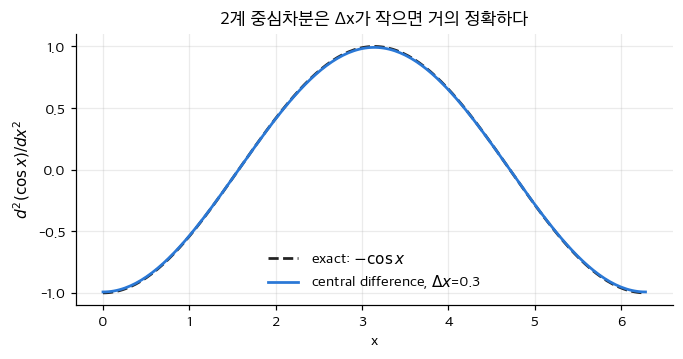

최대 오차 (Δx=0.3):   0.0075
최대 오차 (Δx=0.15):  0.0019   ← Δx를 반으로 줄이면 오차는 약 1/4 (O(Δx²))


In [2]:
x = np.linspace(0, 2*np.pi, 200)
dx_demo = 0.3

f = np.cos
d2_fd = (f(x + dx_demo) - 2*f(x) + f(x - dx_demo)) / dx_demo**2   # 중심차분
d2_exact = -np.cos(x)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(x, d2_exact, color=C_ANA, ls="--", label="exact: $-\\cos x$")
ax.plot(x, d2_fd, color=C_EXP, label=f"central difference, $\\Delta x$={dx_demo}")
ax.set_xlabel("x"); ax.set_ylabel("$d^2(\\cos x)/dx^2$")
ax.legend(frameon=False)
ax.set_title("2계 중심차분은 Δx가 작으면 거의 정확하다")
plt.show()

print(f"최대 오차 (Δx={dx_demo}):   {np.abs(d2_fd - d2_exact).max():.4f}")
dx2 = dx_demo/2
d2_fd2 = (f(x+dx2) - 2*f(x) + f(x-dx2)) / dx2**2
print(f"최대 오차 (Δx={dx2}):  {np.abs(d2_fd2 - d2_exact).max():.4f}   ← Δx를 반으로 줄이면 오차는 약 1/4 (O(Δx²))")


## 2. 문제 정의

모래층 사이에 끼인 두께 20 m의 **점토층(aquitard)** 이 있습니다. 처음에는 점토층 전체의 수두가 100 m였는데,
어느 순간 위·아래 모래층의 수두가 0 m로 떨어졌습니다 (예: 양수). 점토층 안의 과잉수두는 천천히 빠져나갑니다.

**지배방정식** (1D, 균질, 비정류)

$$
\frac{\partial^2 h}{\partial x^2} = \frac{S_s}{K}\,\frac{\partial h}{\partial t}
$$

| 기호 | 값 | 의미 |
|---|---|---|
| $K$ | 0.0001 m/yr | 수리전도도 |
| $S_s$ | 0.0001 1/m | 비저류계수 |
| $L$ | 20 m | 점토층 두께 |
| $D = K/S_s$ | 1 m²/yr | 수리확산계수 (hydraulic diffusivity) |

**초기조건** $h(x, 0) = 100$ m
**경계조건** $h(0, t) = h(L, t) = 0$ m

$D = K/S_s$ 가 1 m²/yr이므로, 수두 변화가 20 m 두께를 "관통"하는 데 대략 $L^2/D \sim$ 수백 년 규모임을 미리 짐작할 수 있습니다.


In [3]:
K   = 1e-4   # m/yr
Ss  = 1e-4   # 1/m
L   = 20.0   # m
h0  = 100.0  # m, 초기 수두
T   = 100.0  # yr, 모사 기간
D   = K/Ss   # m^2/yr, hydraulic diffusivity
print(f"D = K/Ss = {D} m²/yr,   특성시간 L²/D = {L**2/D:.0f} yr")


D = K/Ss = 1.0 m²/yr,   특성시간 L²/D = 400 yr


### 격자(grid)

공간을 $\Delta x$ 간격으로, 시간을 $\Delta t$ 간격으로 나눕니다.

- 공간 절점: $x_i = i\,\Delta x$, $i = 0, 1, \dots, N_x-1$
- 시간 단계: $t^n = n\,\Delta t$, $n = 0, 1, \dots, N_t$

표기: $h_i^n$ = 절점 $i$, 시간단계 $n$에서의 수두.

양쪽 끝 절점($i=0$, $i=N_x-1$)은 경계조건으로 값이 **고정**되어 있으므로, 실제로 풀어야 하는 미지수는 **내부 절점**뿐입니다.


In [4]:
def make_grid(dx, dt):
    nx = int(round(L/dx)) + 1
    nt = int(round(T/dt))
    x  = np.linspace(0, L, nx)
    t  = np.arange(nt+1) * dt
    return x, t, nx, nt

x, t, nx, nt = make_grid(dx=1.0, dt=0.1)
print(f"nx = {nx} 절점,  nt = {nt} 시간단계,  미지수(내부 절점) = {nx-2}")


nx = 21 절점,  nt = 1000 시간단계,  미지수(내부 절점) = 19


## 3. Explicit (양해법) 풀이

지배방정식의 공간항은 **현재 시간 $n$** 에서 중심차분, 시간항은 전진차분으로 씁니다.

$$
\frac{h_{i+1}^{n} - 2h_i^{n} + h_{i-1}^{n}}{\Delta x^2} = \frac{S_s}{K}\,\frac{h_i^{n+1} - h_i^{n}}{\Delta t}
$$

미지수는 $h_i^{n+1}$ 하나뿐이므로 바로 정리됩니다.

$$
\boxed{\;h_i^{n+1} = r\,h_{i-1}^{n} + (1-2r)\,h_i^{n} + r\,h_{i+1}^{n}\;}, \qquad r = \frac{K\,\Delta t}{S_s\,\Delta x^2} = \frac{D\,\Delta t}{\Delta x^2}
$$

> 다음 시간의 값이 **현재 시간의 이웃 세 점의 가중평균**으로 결정됩니다.
> 가중치 $(r,\; 1-2r,\; r)$의 합은 항상 1이지만, $r > 1/2$ 이면 가운데 가중치가 **음수**가 됩니다. 이것이 불안정의 원인입니다.

무차원수 $r$ 은 "한 시간단계 동안 수두 교란이 한 격자 간격을 얼마나 지나가는가"를 나타냅니다.


In [5]:
def solve_explicit(dx, dt):
    x, t, nx, nt = make_grid(dx, dt)
    r = D*dt/dx**2
    h = np.zeros((nt+1, nx))     # h[n, i]
    h[0, 1:-1] = h0              # 초기조건 (내부), 경계는 0
    for n in range(nt):
        h[n+1, 1:-1] = r*h[n, :-2] + (1-2*r)*h[n, 1:-1] + r*h[n, 2:]
    return x, t, h, r

x, t, h_exp, r = solve_explicit(dx=1.0, dt=0.1)
print(f"r = {r:.3f}")


r = 0.100


### 결과 보기

시간에 따른 수두 단면(profile)을 그립니다. 색이 진할수록 나중 시간입니다.


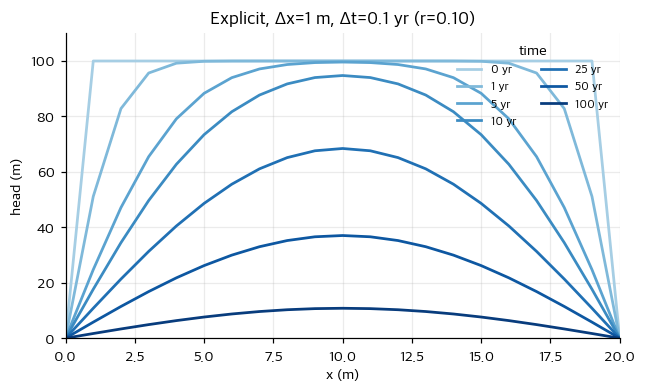

In [6]:
def plot_profiles(x, t, h, times, ax=None, title=None, cmap="Blues"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 3.6))
    cm = plt.get_cmap(cmap)
    for k, tt in enumerate(times):
        n = int(round(tt/(t[1]-t[0])))
        col = cm(0.35 + 0.6*k/max(len(times)-1, 1))
        ax.plot(x, h[n], color=col, label=f"{tt:g} yr")
    ax.set_xlabel("x (m)"); ax.set_ylabel("head (m)")
    ax.set_ylim(0, 110); ax.set_xlim(0, L)
    ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2, title="time")
    if title: ax.set_title(title)
    return ax

plot_profiles(x, t, h_exp, times=[0, 1, 5, 10, 25, 50, 100],
              title=f"Explicit, Δx=1 m, Δt=0.1 yr (r={r:.2f})")
plt.show()


### 안정성(stability): $r$을 키우면 어떻게 될까?

같은 $\Delta x$에서 $\Delta t$만 늘려 봅니다. $r \le 0.5$ 와 $r > 0.5$ 의 차이를 보세요.


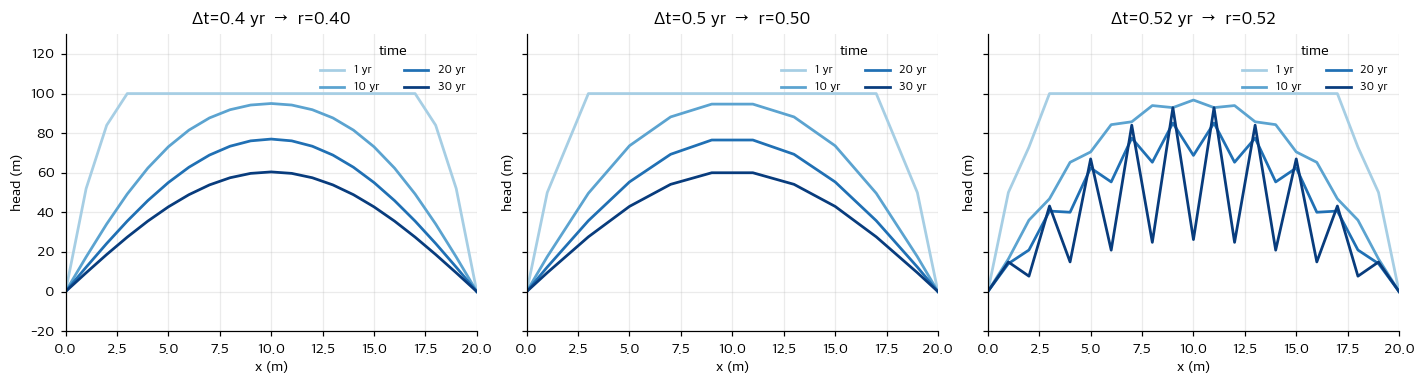

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, dt_ in zip(axes, [0.4, 0.5, 0.52]):
    x_, t_, h_, r_ = solve_explicit(dx=1.0, dt=dt_)
    plot_profiles(x_, t_, h_, times=[1, 10, 20, 30], ax=ax,
                  title=f"Δt={dt_} yr  →  r={r_:.2f}")
axes[0].set_ylim(-20, 130)
plt.tight_layout(); plt.show()


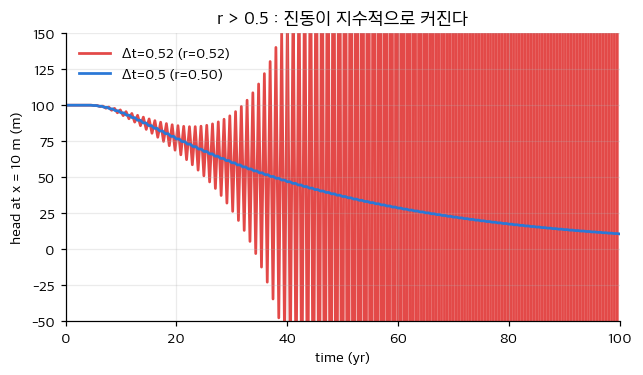

In [8]:
# r > 0.5일 때 오차가 시간에 따라 어떻게 커지는지 (가운데 절점)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for dt_, col, z in [(0.52, "#e34948", 1), (0.5, C_EXP, 2)]:
    x_, t_, h_, r_ = solve_explicit(dx=1.0, dt=dt_)
    ax.plot(t_, h_[:, len(x_)//2], color=col, zorder=z, label=f"Δt={dt_} (r={r_:.2f})")
ax.set_xlim(0, 100); ax.set_ylim(-50, 150)
ax.set_xlabel("time (yr)"); ax.set_ylabel("head at x = 10 m (m)")
ax.legend(frameon=False)
ax.set_title("r > 0.5 : 진동이 지수적으로 커진다")
plt.show()


**Explicit 방법의 안정조건**

$$
r = \frac{D\,\Delta t}{\Delta x^2} \le \frac{1}{2}
\quad\Longrightarrow\quad
\Delta t \le \frac{\Delta x^2}{2D}
$$

$\Delta x$를 반으로 줄이면 $\Delta t$는 **1/4**로 줄여야 합니다. 공간 해상도를 높일수록 시간단계 수가 급격히 늘어나는 것이 explicit 방법의 근본적 한계입니다.

| $\Delta x$ (m) | 허용 $\Delta t_{max}$ (yr) | 100년 모사에 필요한 단계 수 |
|---|---|---|
| 1 | 0.5 | 200 |
| 0.5 | 0.125 | 800 |
| 0.1 | 0.005 | 20,000 |


## 4. Implicit (음해법) 풀이

공간항을 **다음 시간 $n+1$** 에서 평가합니다. 바뀐 것은 위첨자 하나뿐입니다.

$$
\frac{h_{i+1}^{n+1} - 2h_i^{n+1} + h_{i-1}^{n+1}}{\Delta x^2} = \frac{S_s}{K}\,\frac{h_i^{n+1} - h_i^{n}}{\Delta t}
$$

미지수 $h^{n+1}$ 을 왼쪽에, 아는 값 $h^n$ 을 오른쪽에 모으면

$$
\boxed{\;-r\,h_{i-1}^{n+1} + (1+2r)\,h_i^{n+1} - r\,h_{i+1}^{n+1} = h_i^{n}\;}
$$

한 식에 **미지수가 세 개**입니다. 모든 내부 절점에 대해 이 식을 세우면 연립방정식이 됩니다.

$$
\underbrace{\begin{pmatrix}
1+2r & -r    &        &        \\
-r   & 1+2r  & -r     &        \\
     & \ddots& \ddots & \ddots \\
     &       & -r     & 1+2r
\end{pmatrix}}_{\mathbf{A}\ (\text{tridiagonal})}
\begin{pmatrix} h_1 \\ h_2 \\ \vdots \\ h_{N-2} \end{pmatrix}^{n+1}
=
\begin{pmatrix} h_1 \\ h_2 \\ \vdots \\ h_{N-2} \end{pmatrix}^{n}
+
\begin{pmatrix} r\,h_0 \\ 0 \\ \vdots \\ r\,h_{N-1} \end{pmatrix}
$$

마지막 벡터는 경계값이 들어가는 항입니다. 이 문제에서는 경계가 0이라 사라지지만, 일반적으로는 꼭 넣어야 합니다.

매 시간단계마다 $\mathbf{A}\,\mathbf{h}^{n+1} = \mathbf{b}$ 를 풉니다. $\mathbf{A}$는 시간에 따라 변하지 않습니다.


In [9]:
def build_A(r, n_unknown):
    main = np.full(n_unknown,   1 + 2*r)
    off  = np.full(n_unknown-1, -r)
    return np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

A_small = build_A(r=0.1, n_unknown=5)
print("예: r=0.1, 내부 절점 5개일 때 A =")
print(np.round(A_small, 2))


예: r=0.1, 내부 절점 5개일 때 A =
[[ 1.2 -0.1  0.   0.   0. ]
 [-0.1  1.2 -0.1  0.   0. ]
 [ 0.  -0.1  1.2 -0.1  0. ]
 [ 0.   0.  -0.1  1.2 -0.1]
 [ 0.   0.   0.  -0.1  1.2]]


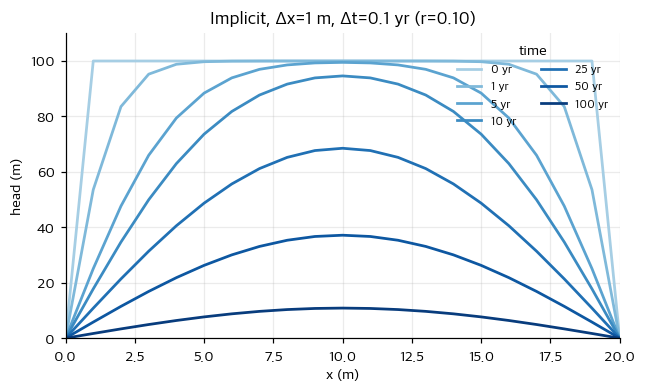

In [10]:
def solve_implicit(dx, dt, h_left=0.0, h_right=0.0):
    x, t, nx, nt = make_grid(dx, dt)
    r = D*dt/dx**2
    A = build_A(r, nx-2)
    h = np.zeros((nt+1, nx))
    h[0, 1:-1] = h0
    h[:, 0], h[:, -1] = h_left, h_right
    for n in range(nt):
        b = h[n, 1:-1].copy()
        b[0]  += r*h_left          # 경계 기여 (여기서는 0)
        b[-1] += r*h_right
        h[n+1, 1:-1] = np.linalg.solve(A, b)
    return x, t, h, r

x, t, h_imp, r = solve_implicit(dx=1.0, dt=0.1)
plot_profiles(x, t, h_imp, times=[0, 1, 5, 10, 25, 50, 100],
              title=f"Implicit, Δx=1 m, Δt=0.1 yr (r={r:.2f})")
plt.show()


> `np.linalg.solve(A, b)` 대신 `invA = np.linalg.inv(A)` 를 한 번 구해 두고 `invA @ b` 를 반복해도 됩니다.
> 수업 자료의 기존 코드가 그 방식입니다. 절점 수가 많아지면 역행렬은 메모리와 정확도 면에서 불리하고,
> 삼중대각 행렬은 **Thomas 알고리즘**으로 $O(N)$에 풀 수 있습니다 (`scipy.linalg.solve_banded`).

### Implicit은 $r$이 커도 안정한가?

Explicit이 터졌던 $r > 0.5$, 그리고 훨씬 큰 $r$ 에서도 돌려 봅니다.


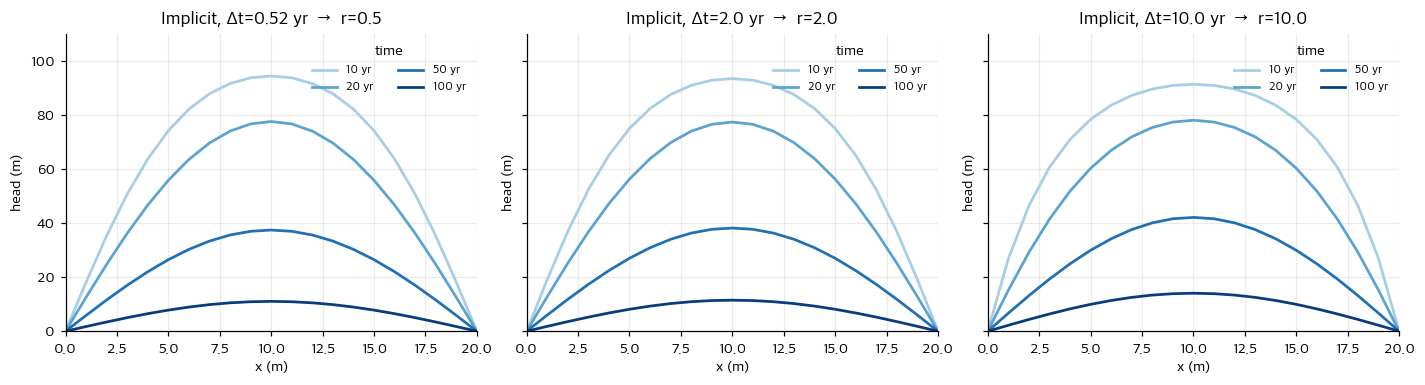

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, dt_ in zip(axes, [0.52, 2.0, 10.0]):
    x_, t_, h_, r_ = solve_implicit(dx=1.0, dt=dt_)
    plot_profiles(x_, t_, h_, times=[10, 20, 50, 100], ax=ax,
                  title=f"Implicit, Δt={dt_} yr  →  r={r_:.1f}")
plt.tight_layout(); plt.show()


**Implicit 방법은 $r$에 관계없이 무조건 안정(unconditionally stable)** 합니다.
$\mathbf{A}$의 가중치 $(-r,\;1+2r,\;-r)$ 를 보면, 다음 시간의 값은 이웃값의 "평균 쪽으로 끌려가는" 구조라 절대 발산하지 않습니다.

단, 안정하다는 것과 정확하다는 것은 다릅니다. $\Delta t = 10$ yr 결과는 발산하지는 않지만 초기 단면이 뭉개져 있습니다.


## 5. 해석해(analytical solution)와 비교

이 문제는 Fourier 급수로 정확히 풀립니다 (열전도 방정식의 고전적 해).

$$
h(x,t) = \sum_{m=1,3,5,\dots}^{\infty} \frac{4h_0}{m\pi}\,
\exp\!\left(-\frac{m^2\pi^2 D\,t}{L^2}\right)\sin\!\left(\frac{m\pi x}{L}\right)
$$

짝수 $m$ 항은 0이 되므로 홀수 항만 남습니다. 수치해의 **정확도**를 평가하는 기준으로 씁니다.


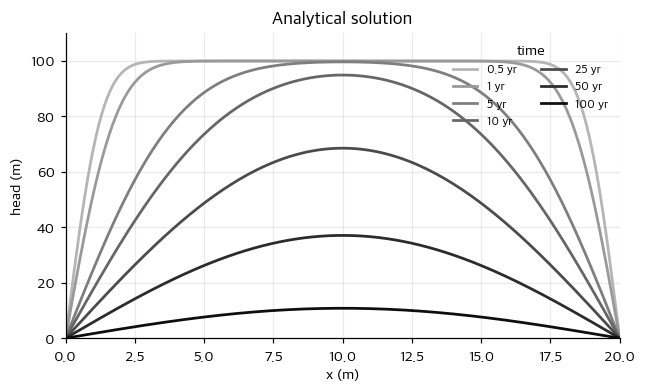

In [12]:
def h_analytical(x, t, n_terms=200):
    x = np.asarray(x, dtype=float); h = np.zeros_like(x)
    for m in range(1, 2*n_terms, 2):          # 홀수 항만
        h += 4*h0/(m*np.pi) * np.exp(-(m*np.pi/L)**2 * D*t) * np.sin(m*np.pi*x/L)
    return h if h.ndim else float(h)

x_fine = np.linspace(0, L, 201)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
cm = plt.get_cmap("Greys")
for k, tt in enumerate([0.5, 1, 5, 10, 25, 50, 100]):
    ax.plot(x_fine, h_analytical(x_fine, tt), color=cm(0.4 + 0.55*k/6), label=f"{tt:g} yr")
ax.set_xlabel("x (m)"); ax.set_ylabel("head (m)"); ax.set_ylim(0, 110); ax.set_xlim(0, L)
ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2, title="time")
ax.set_title("Analytical solution")
plt.show()


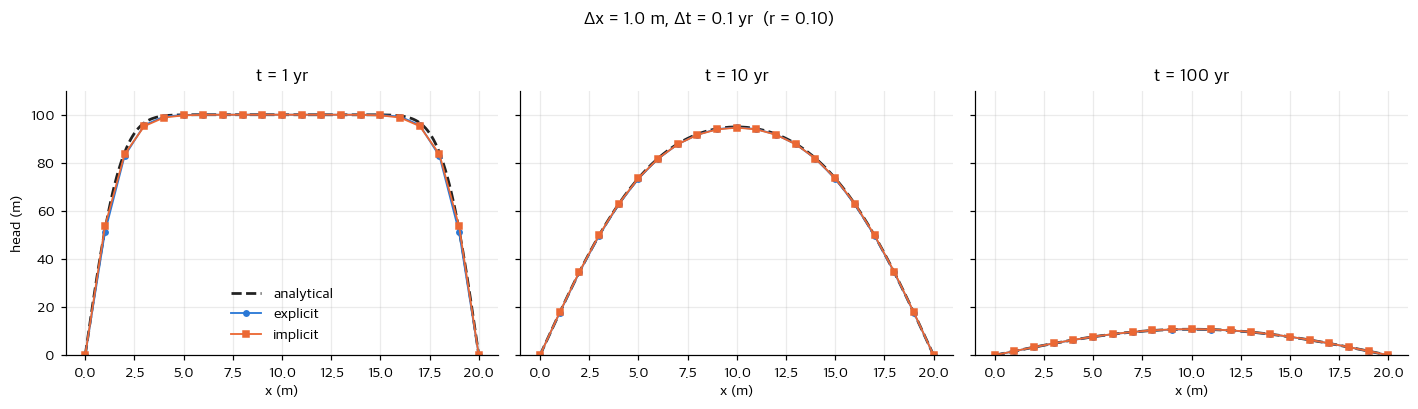

In [13]:
dx, dt = 1.0, 0.1
x, t, h_exp, r = solve_explicit(dx, dt)
_, _, h_imp, _ = solve_implicit(dx, dt)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, tt in zip(axes, [1, 10, 100]):
    n = int(round(tt/dt))
    ax.plot(x_fine, h_analytical(x_fine, tt), color=C_ANA, ls="--", label="analytical")
    ax.plot(x, h_exp[n], color=C_EXP, marker="o", ms=3.5, lw=1.2, label="explicit")
    ax.plot(x, h_imp[n], color=C_IMP, marker="s", ms=3.5, lw=1.2, label="implicit")
    ax.set_title(f"t = {tt} yr"); ax.set_xlabel("x (m)")
axes[0].set_ylabel("head (m)"); axes[0].set_ylim(0, 110)
axes[0].legend(frameon=False)
plt.suptitle(f"Δx = {dx} m, Δt = {dt} yr  (r = {r:.2f})", y=1.02)
plt.tight_layout(); plt.show()


이 정도 해상도에서는 셋이 거의 겹칩니다. 차이를 보려면 **오차**를 직접 그려야 합니다.


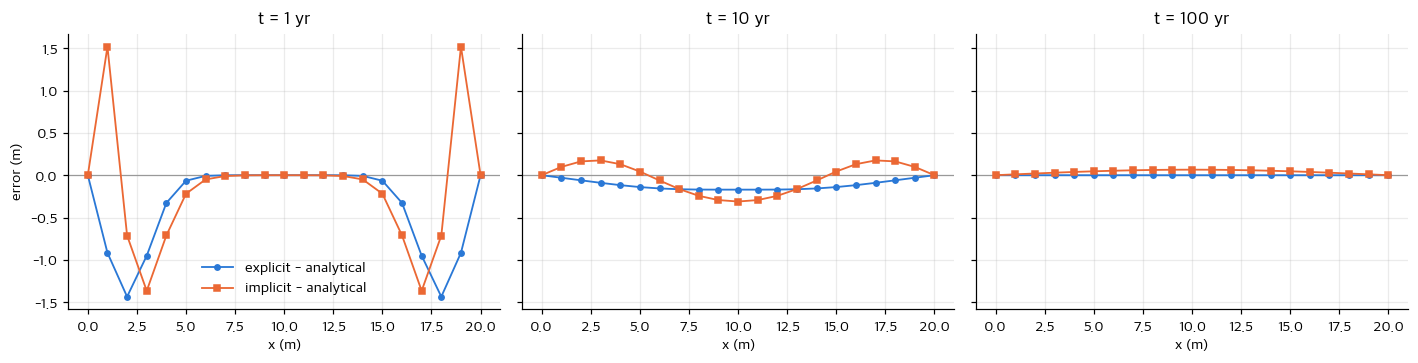

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, tt in zip(axes, [1, 10, 100]):
    n = int(round(tt/dt)); ha = h_analytical(x, tt)
    ax.axhline(0, color="#999", lw=0.8)
    ax.plot(x, h_exp[n] - ha, color=C_EXP, marker="o", ms=3.5, lw=1.2, label="explicit - analytical")
    ax.plot(x, h_imp[n] - ha, color=C_IMP, marker="s", ms=3.5, lw=1.2, label="implicit - analytical")
    ax.set_title(f"t = {tt} yr"); ax.set_xlabel("x (m)")
axes[0].set_ylabel("error (m)"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()


**관찰**
- 오차는 초기(t = 1 yr)에 가장 크고, 경계 근처에서 큽니다. 단면이 급하게 변하는 곳에서 차분 근사가 거칠어지기 때문입니다.
- **Implicit은 항상 explicit보다 높게** 나옵니다. 시간 오차의 부호가 서로 반대이기 때문입니다.
  Explicit은 "현재" 기울기로 전진하고, implicit은 "다음" 기울기로 전진합니다. 수두가 감소하는 문제에서는 각각 과소·과대 추정하는 방향입니다.
- 그런데 t = 1, 10 yr에서는 둘 다 해석해보다 낮습니다. $\Delta x = 1$ m의 **공간 이산화 오차**가 두 방법에 공통으로 깔려 있고, 이 문제에서는 그 부호가 음(−)이기 때문입니다.
  즉 전체 오차 = 공간 오차(공통) + 시간 오차(부호 반대).
- t = 100 yr에서 explicit 오차가 거의 0인 것은 우연한 상쇄입니다. $r = 0.1$ 근처에서는 explicit의 시간 오차와 공간 오차가 서로 지워집니다 ($r = 1/6$에서 정확히 상쇄되는 것이 알려져 있음).
- 두 방법 모두 시간 오차는 $O(\Delta t)$ 로 같습니다. **정확도에서는 어느 쪽이 본질적으로 우월하지 않습니다.**


## 6. Explicit vs. Implicit 종합 비교

### 6.1 $\Delta t$를 바꿔 가며 오차 비교

$\Delta x = 1$ m 고정, $\Delta t$를 0.01 → 0.5 yr까지 바꿉니다. explicit은 $r \le 0.5$ 즉 $\Delta t \le 0.5$ 까지만 가능합니다.


In [15]:
def rms_error(x, t, h, times=(1, 10, 100)):
    dt_ = t[1]-t[0]
    errs = []
    for tt in times:
        k = tt/dt_
        if abs(k - round(k)) > 1e-9:          # 그 시각에 시간단계가 없으면 평가 불가
            errs.append(np.nan); continue
        errs.append(np.sqrt(np.mean((h[int(round(k))] - h_analytical(x, tt))**2)))
    return np.array(errs)

dts = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
rows = []
for dt_ in dts:
    r_ = D*dt_/1.0**2
    e_imp = rms_error(*solve_implicit(1.0, dt_)[:3])
    e_exp = rms_error(*solve_explicit(1.0, dt_)[:3]) if r_ <= 0.5 else np.full(3, np.nan)
    rows.append((dt_, r_, *e_exp, *e_imp, r_ <= 0.5))

print(f"{'Δt':>6} {'r':>5} | {'explicit RMS (m)':^26} | {'implicit RMS (m)':^26}")
print(f"{'':>6} {'':>5} | {'t=1':>8} {'t=10':>8} {'t=100':>8} | {'t=1':>8} {'t=10':>8} {'t=100':>8}")
fmt = lambda v: f"{'n/a':>8}" if np.isnan(v) else f"{v:8.3f}"
for row in rows:
    s = f"{row[0]:>6g} {row[1]:>5.2f} | "
    s += (" ".join(fmt(v) for v in row[2:5]) if row[8] else f"{'unstable':^26}") + " | "
    s += " ".join(fmt(v) for v in row[5:8])
    print(s)
print("n/a : Δt가 그 시각을 정확히 지나지 않아 비교 불가")


    Δt     r |      explicit RMS (m)      |      implicit RMS (m)     
             |      t=1     t=10    t=100 |      t=1     t=10    t=100
  0.01  0.01 |    0.519    0.126    0.020 |    0.533    0.131    0.025
  0.02  0.02 |    0.517    0.124    0.018 |    0.544    0.134    0.027
  0.05  0.05 |    0.529    0.121    0.011 |    0.592    0.146    0.034
   0.1  0.10 |    0.611    0.127    0.000 |    0.707    0.172    0.045
   0.2  0.20 |    0.927    0.171    0.023 |    0.994    0.235    0.068
   0.5  0.50 |    3.114    0.595    0.102 |    1.894    0.456    0.136
     1  1.00 |          unstable          |    3.157    0.838    0.249
     2  2.00 |          unstable          |      n/a    1.588    0.474
     5  5.00 |          unstable          |      n/a    3.672    1.147
n/a : Δt가 그 시각을 정확히 지나지 않아 비교 불가


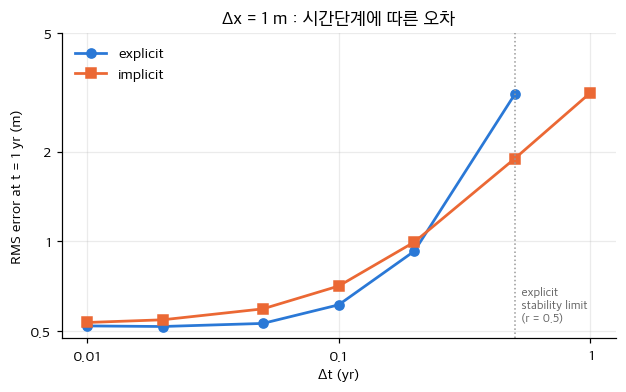

In [16]:
rows = np.array(rows, dtype=float)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(rows[:, 0], rows[:, 2], color=C_EXP, marker="o", label="explicit")
ax.plot(rows[:, 0], rows[:, 5], color=C_IMP, marker="s", label="implicit")
ax.axvline(0.5, color="#999", ls=":", lw=1)
ax.text(0.5, 0.05, "  explicit\n  stability limit\n  (r = 0.5)", fontsize=8, color="#666",
        va="bottom", transform=ax.get_xaxis_transform())
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([0.01, 0.1, 1.0]); ax.set_xticklabels(["0.01", "0.1", "1"])
ax.set_yticks([0.5, 1, 2, 5]); ax.set_yticklabels(["0.5", "1", "2", "5"]); ax.minorticks_off()
ax.set_xlabel("Δt (yr)"); ax.set_ylabel("RMS error at t = 1 yr (m)")
ax.legend(frameon=False)
ax.set_title("Δx = 1 m : 시간단계에 따른 오차")
plt.show()


- $\Delta t \le 0.05$ yr에서는 오차가 약 0.5 m에서 **더 이상 줄지 않습니다**. 남은 것은 $\Delta x = 1$ m에서 오는 공간 오차이고, $\Delta t$를 아무리 줄여도 없어지지 않습니다. 공간 오차를 줄이려면 $\Delta x$를 줄여야 합니다 (6.2절).
- $\Delta t$가 커지면 시간 오차가 그 위에 더해져 오차가 커집니다. 같은 $\Delta t$에서 두 방법의 정확도는 거의 같습니다.
- $\Delta t = 0.5$ ($r = 0.5$, 안정 한계)에서 explicit의 오차가 implicit보다 갑자기 커집니다. 발산은 안 하지만 가중치 $(1-2r) = 0$이라 짝수·홀수 절점이 번갈아 튀는 **체커보드 진동**이 나타납니다 (7절 문제 2).
- 결정적 차이는 **얼마나 큰 $\Delta t$를 쓸 수 있는가**입니다. Implicit은 $\Delta t = 5$ yr에서도 돌아갑니다. 정확하지는 않지만 안정합니다.

### 6.2 $\Delta x$를 줄이면? — explicit의 비용 문제

공간 해상도를 높일수록 explicit은 $\Delta t \le \Delta x^2/2D$ 제약에 묶입니다.
같은 수준의 오차를 얻는 데 드는 **시간단계 수**와 **계산 시간**을 비교합니다.


In [17]:
import time

print(f"{'Δx':>5} | {'explicit':^34} | {'implicit (Δt=0.1 fixed)':^34}")
print(f"{'':>5} | {'Δt_max':>7} {'steps':>7} {'time(s)':>8} {'RMS@1yr':>8} | {'Δt':>7} {'steps':>7} {'time(s)':>8} {'RMS@1yr':>8}")
for dx_ in [1.0, 0.5, 0.25, 0.1]:
    dt_max = dx_**2/(2*D)                     # 안정조건 한계
    t0 = time.perf_counter(); xe, te, he, _ = solve_explicit(dx_, dt_max); t_e = time.perf_counter()-t0
    t0 = time.perf_counter(); xi, ti, hi, _ = solve_implicit(dx_, 0.1);    t_i = time.perf_counter()-t0
    print(f"{dx_:>5} | {dt_max:>7.4f} {len(te)-1:>7d} {t_e:>8.3f} {rms_error(xe,te,he)[0]:>8.3f}"
          f" | {0.1:>7.4f} {len(ti)-1:>7d} {t_i:>8.3f} {rms_error(xi,ti,hi)[0]:>8.3f}")


   Δx |              explicit              |      implicit (Δt=0.1 fixed)      
      |  Δt_max   steps  time(s)  RMS@1yr |      Δt   steps  time(s)  RMS@1yr
  1.0 |  0.5000     200    0.002    3.114 |  0.1000    1000    0.032    0.707
  0.5 |  0.1250     800    0.002    0.831 |  0.1000    1000    0.047    0.510
 0.25 |  0.0312    3200    0.006    0.211 |  0.1000    1000    0.132    0.480


  0.1 |  0.0050   20000    0.100    0.034 |  0.1000    1000    0.526    0.475


$\Delta x$를 10배 줄이면 explicit의 단계 수는 **100배** 늘어납니다. Implicit은 $\Delta t$를 그대로 둘 수 있습니다.

- Explicit은 $\Delta x$를 줄일수록 $\Delta t$도 강제로 작아져서, 결과적으로 오차가 빠르게 줄어듭니다. 대신 단계 수가 폭증합니다.
- Implicit은 $\Delta t = 0.1$ yr로 고정했기 때문에 $\Delta x$를 줄여도 오차가 약 0.48 m에서 멈춥니다. 이번엔 **시간 오차**가 바닥입니다. $\Delta t$를 줄이면 더 내려가고, 안정성 걱정 없이 원하는 만큼 줄일 수 있습니다.
- 여기서 implicit이 느린 이유는 `np.linalg.solve`가 매 단계 $N \times N$ 행렬을 통째로 분해하기 때문입니다. 삼중대각 전용 풀이(Thomas 알고리즘, `scipy.linalg.solve_banded`)를 쓰면 한 단계 비용이 explicit과 같은 $O(N)$이 됩니다.

### 6.3 정리

| | Explicit | Implicit |
|---|---|---|
| 한 단계의 계산 | 이웃 3점 가중평균, 행렬 없음 | 삼중대각 연립방정식 풀이 |
| 코드 난이도 | 쉬움 | 행렬 구성 필요 |
| 안정성 | **조건부**: $r = D\Delta t/\Delta x^2 \le 1/2$ | **무조건 안정** |
| 시간 정확도 | $O(\Delta t)$ | $O(\Delta t)$ |
| 공간 정확도 | $O(\Delta x^2)$ | $O(\Delta x^2)$ |
| 오차의 부호 (감소 문제) | 과소 추정 | 과대 추정 |
| 격자를 촘촘히 할 때 | $\Delta t$가 $\Delta x^2$으로 줄어 비용 급증 | $\Delta t$ 자유롭게 선택 |
| 실무 (MODFLOW 등) | 거의 쓰지 않음 | 표준 |

> **Crank–Nicolson**: 두 방법의 산술평균 (공간항을 $n$과 $n+1$에서 반씩). 무조건 안정이면서 시간 정확도가 $O(\Delta t^2)$ 로 올라갑니다.
> 위 오차 그림에서 explicit과 implicit의 오차가 부호만 반대인 것을 봤으니, 둘을 평균하면 왜 좋아지는지 짐작할 수 있습니다.


## 7. 생각해 볼 문제

1. $\Delta x = 1$ m, $\Delta t = 0.1$ yr일 때 100년 후 점토층 중앙에 남아 있는 과잉수두는 얼마인가? 해석해와 몇 % 차이가 나는가?
2. Explicit 코드에서 $r = 0.5$ 를 정확히 쓰면 가운데 가중치 $(1-2r)$이 0이 된다. 이때 $h_i^{n+1}$은 무엇으로 결정되는가? 결과 그림에서 어떤 특징이 보이는가?
3. 위쪽 경계를 $h(0,t) = 0$ 대신 $h(0,t) = 50$ m로 바꾸면 implicit 코드의 어느 부분을 고쳐야 하는가? (`solve_implicit`의 `h_left` 인자를 써서 확인해 보라.)
4. Crank–Nicolson 방법을 구현해서 같은 $\Delta t$에서 오차가 얼마나 줄어드는지 확인해 보라.
   힌트: $-\tfrac{r}{2}h_{i-1}^{n+1} + (1+r)h_i^{n+1} - \tfrac{r}{2}h_{i+1}^{n+1} = \tfrac{r}{2}h_{i-1}^{n} + (1-r)h_i^{n} + \tfrac{r}{2}h_{i+1}^{n}$


In [18]:
# 문제 1 바로 확인
x, t, h_imp, _ = solve_implicit(1.0, 0.1)
_, _, h_exp, _ = solve_explicit(1.0, 0.1)
ic = len(x)//2
ha100 = h_analytical(10.0, 100.0)
print(f"100년 후 x=10 m 수두:  analytical {ha100:.3f} m,  explicit {h_exp[-1, ic]:.3f} m,  implicit {h_imp[-1, ic]:.3f} m")


100년 후 x=10 m 수두:  analytical 10.798 m,  explicit 10.797 m,  implicit 10.863 m
